# Praktikum Sub-CPMK-4 &mdash; Transformasi Ruang Warna untuk Analisis dan Pemrosesan Citra

**Pengolahan Citra Digital (IF2514505)** &nbsp;|&nbsp; Semester 5 &nbsp;|&nbsp; 1 SKS Praktikum &nbsp;|&nbsp; Durasi sasaran 135 menit (rentang 120&ndash;150)

**Program Studi Informatika &mdash; Institut Teknologi Kalimantan**

---

| | |
|---|---|
| **Nama** | Bryan Fitur Ayni |
| **NIM** | 11241020 |
| **Kelas / Kelompok** | PCD A |
| **Tanggal praktikum** | 18 November 2026 |

---

### Capaian yang diukur
**Sub-CPMK-4**: Mahasiswa mampu menerapkan transformasi ruang warna citra untuk keperluan analisis dan pemrosesan citra.
Indikator: (1) ketepatan konversi antarruang warna dan pemilihan ruang warna yang sesuai persoalan; (2) ketepatan laporan praktikum sesuai kaidah penulisan ilmiah.

### Rujukan
Gonzalez, R.C. dan Woods, R.E. (2018) *Digital Image Processing*, edisi ke-4, Bab 6 (§6.1&ndash;6.8). Nomor persamaan mengikuti buku tersebut.
HSV tidak dibahas Gonzalez; definisinya mengikuti Smith (1978) dan dokumentasi OpenCV.

### Petunjuk pengerjaan
1. Jalankan sel berurutan. Sel bertanda `# TODO` wajib Anda lengkapi sendiri.
2. Setiap blok **Analisis** diisi kalimat Anda sendiri dan **wajib memuat angka** dari keluaran Anda.
3. Citra uji dibangkitkan di dalam notebook (benih tetap); citra `coffee` diambil dari `skimage.data`. **Tidak perlu mengunggah berkas.**
4. Semua citra di notebook ini berurutan kanal **RGB**. Untuk OpenCV pakai kode `cv2.COLOR_RGB2...`, bukan `BGR2...`.
5. Masker kebenaran (`gt_...`) hanya dipakai untuk **menilai** hasil, bukan untuk menentukan ambang.
6. Bagian **[Pengayaan]** boleh dilewati; jalur inti selesai dalam &plusmn;120 menit.
7. Kumpulkan dalam keadaan **sudah dijalankan penuh** dengan nama `PraktikumPCD_SubCPMK4_NIM_Nama.ipynb`, beserta laporan (Bagian 6).

| Bagian | Isi | Menit |
|---|---|---|
| 0 | Persiapan, citra uji, jebakan BGR | 10 |
| 1 | Konversi dari definisi: HSI, HSV, Lab, dan skala OpenCV (§6.2) | 25 |
| 2 | Pencahayaan dan derau: apa yang bertahan, apa yang goyah (§6.2, §6.8) | 20 |
| 3 | Pemrosesan citra berwarna: ekualisasi histogram (§6.4&ndash;6.5) | 20 |
| 4 | Segmentasi berbasis warna: RGB, HSV, Lab (§6.5, §6.7) | 30 |
| 5 | Studi kasus: pencarian rakit penolong di perairan | 20 |
| 6 | Laporan ilmiah dan pengumpulan | 10 |


## Bagian 0 &mdash; Persiapan (10 menit)
Jalankan sel berikut **tanpa diubah**.

NumPy 2.5.5 | OpenCV 5.1.0


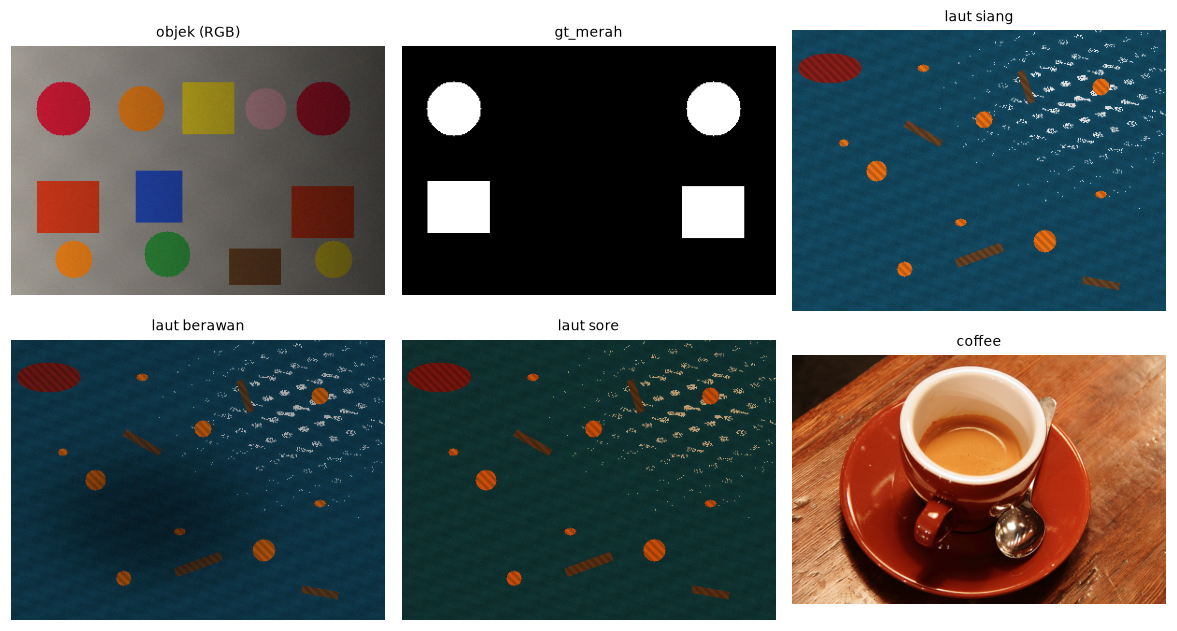

In [1]:
# Sel persiapan — jalankan tanpa diubah
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage import data, color

plt.rcParams['figure.dpi'] = 110
print('NumPy', np.__version__, '| OpenCV', cv2.__version__)

"""Pembangkit citra uji sintetis Sub-CPMK-4 (benih acak tetap, hanya NumPy).

Semua citra dikembalikan sebagai RGB uint8 (urutan R, G, B). Untuk OpenCV gunakan
cv2.cvtColor(img, cv2.COLOR_RGB2...) atau ubah dulu ke BGR.
Model pencahayaan sengaja disederhanakan: perkalian langsung pada nilai piksel tersandi.
"""
import numpy as np

BENIH = 2027


def _grid(h, w):
    return np.mgrid[0:h, 0:w].astype(np.float64)


def _ke_uint8(x):
    return np.clip(np.floor(255 * x + 0.5), 0, 255).astype(np.uint8)


def _cakram(yy, xx, cy, cx, r):
    return (yy - cy) ** 2 + (xx - cx) ** 2 <= r ** 2


def _kotak(yy, xx, y0, x0, y1, x1):
    return (yy >= y0) & (yy < y1) & (xx >= x0) & (xx < x1)


# ---------------------------------------------------------------- adegan objek berwarna
WARNA_OBJEK = {
    "merah_tua":  (0.78, 0.10, 0.20),   # hue ≈ 351° (sisi magenta dari merah)
    "merah_bata": (0.80, 0.22, 0.10),   # hue ≈ 10°
    "jingga":     (0.92, 0.50, 0.10),
    "kuning":     (0.90, 0.80, 0.15),
    "hijau":      (0.20, 0.60, 0.25),
    "biru":       (0.15, 0.30, 0.75),
    "cokelat":    (0.45, 0.28, 0.16),
    "merah_muda": (0.85, 0.62, 0.66),
}


def objek_warna(rng, h=240, w=360, gelap_kanan=0.35, sigma=0.010):
    """Delapan jenis objek di atas latar netral, pencahayaan menurun linear ke kanan.

    Mengembalikan (citra RGB uint8, masker kebenaran objek merah, peta pencahayaan).
    Objek merah: dua di sisi terang (kiri) dan dua di sisi gelap (kanan).
    """
    yy, xx = _grid(h, w)
    img = np.empty((h, w, 3))
    img[...] = (0.62, 0.60, 0.57)
    img += 0.015 * np.sin(yy / 9.0)[..., None] * np.cos(xx / 13.0)[..., None]
    gt = np.zeros((h, w), bool)
    letak = [  # (warna, bentuk, parameter, merah?)
        ("merah_tua", "c", (60, 50, 26), True), ("merah_bata", "k", (130, 25, 180, 85), True),
        ("merah_tua", "c", (60, 300, 26), True), ("merah_bata", "k", (135, 270, 185, 330), True),
        ("jingga", "c", (60, 125, 22), False), ("kuning", "k", (35, 165, 85, 215), False),
        ("hijau", "c", (200, 150, 22), False), ("biru", "k", (120, 120, 170, 165), False),
        ("cokelat", "k", (195, 210, 230, 260), False), ("merah_muda", "c", (60, 245, 20), False),
        ("jingga", "c", (205, 60, 18), False), ("kuning", "c", (205, 310, 18), False),
    ]
    for nama, bentuk, p, merah in letak:
        m = _cakram(yy, xx, *p) if bentuk == "c" else _kotak(yy, xx, *p)
        img[m] = WARNA_OBJEK[nama]
        if merah:
            gt |= m
    cahaya = 1.0 - (1.0 - gelap_kanan) * xx / (w - 1)
    img = img * cahaya[..., None] + rng.normal(0, sigma, img.shape)
    return _ke_uint8(img), gt, cahaya


# ---------------------------------------------------------------- adegan perairan (SAR)
RAKIT = (0.95, 0.45, 0.08)        # jingga keselamatan (sekoci/rompi)
KAYU = (0.42, 0.27, 0.15)         # puing kayu: corak dekat jingga, gelap, kurang pekat
LAMBUNG = (0.55, 0.12, 0.10)      # cat lambung bawah air (merah tua)
LAUT = (0.07, 0.27, 0.36)


def _geometri_perairan(rng, h, w):
    """Geometri tetap (gelombang, kilau, objek) yang sama untuk semua kondisi cahaya."""
    yy, xx = _grid(h, w)
    gel = (0.55 * np.sin(2 * np.pi * (yy / 23.0 + xx / 61.0)) + 0.35 * np.sin(2 * np.pi * (yy / 11.0 - xx / 37.0))
           + 0.25 * np.sin(2 * np.pi * (xx / 17.0 + yy / 53.0)))
    tekstur = 1.0 + 0.10 * gel / 1.15 + rng.normal(0, 0.03, (h, w))
    # kilau matahari: bercak terang di kanan atas, dekat puncak gelombang
    pusat_kilau = np.exp(-(((yy - 70) / 55.0) ** 2 + ((xx - 310) / 70.0) ** 2))
    kilau = (gel > 0.55) & (rng.random((h, w)) < 0.9 * pusat_kilau)
    obj = {}
    rakit = [(150, 90, 11), (95, 205, 9), (225, 270, 12), (255, 120, 8), (60, 330, 9)]
    rompi = [(175, 330, 4, 6), (205, 180, 4, 6), (120, 55, 4, 5), (40, 140, 4, 6)]
    m_rakit = np.zeros((h, w), bool)
    for cy, cx, r in rakit:
        m_rakit |= _cakram(yy, xx, cy, cx, r)
    for cy, cx, a, b in rompi:
        m_rakit |= ((yy - cy) / a) ** 2 + ((xx - cx) / b) ** 2 <= 1
    m_kayu = np.zeros((h, w), bool)
    for cy, cx, dl, dw, t in [(110, 140, 22, 4, 30), (240, 200, 26, 5, -20), (60, 250, 18, 4, 70), (270, 330, 20, 4, 10)]:
        tr = np.deg2rad(t)
        u, v = (xx - cx) * np.cos(tr) + (yy - cy) * np.sin(tr), -(xx - cx) * np.sin(tr) + (yy - cy) * np.cos(tr)
        m_kayu |= (np.abs(u) <= dl) & (np.abs(v) <= dw)
    m_lambung = ((yy - 40) / 16.0) ** 2 + ((xx - 40) / 34.0) ** 2 <= 1
    obj.update(rakit=m_rakit & ~m_lambung, kayu=m_kayu & ~m_rakit, lambung=m_lambung, kilau=kilau & ~m_rakit & ~m_kayu & ~m_lambung)
    rona = 0.88 + 0.12 * np.cos(2 * np.pi * (yy - xx) / 9.0)        # bayangan lipatan di permukaan objek
    return yy, xx, tekstur, obj, rona


def perairan(rng, kondisi="siang", h=300, w=400, sigma=0.010):
    """Citra udara permukaan laut pascakecelakaan: rakit/rompi jingga, puing kayu, lambung terbalik, kilau.

    kondisi: 'siang' (cahaya putih merata), 'berawan' (redup 0,75 + bayangan awan 0,45),
             'sore' (cahaya hangat: kanal dikali (1,00; 0,82; 0,60) × 0,85).
    Geometri sama untuk semua kondisi (benih geometri tetap); derau berbeda per kondisi.
    Mengembalikan (citra RGB uint8, masker kebenaran rakit/rompi, kamus masker lain).
    """
    yy, xx, tekstur, obj, rona = _geometri_perairan(np.random.default_rng(BENIH + 1), h, w)
    img = np.empty((h, w, 3))
    img[...] = LAUT
    img *= tekstur[..., None]
    img[obj["kilau"]] = 0.80 + 0.15 * rng.random((obj["kilau"].sum(), 1))
    for nama, warna in (("lambung", LAMBUNG), ("kayu", KAYU), ("rakit", RAKIT)):
        m = obj[nama]
        img[m] = np.array(warna) * rona[m][:, None]
    if kondisi == "siang":
        cahaya = np.ones((h, w, 3))
    elif kondisi == "berawan":
        awan = np.exp(-(((yy - 190) / 70.0) ** 2 + ((xx - 150) / 110.0) ** 2) ** 1.5)
        cahaya = np.repeat((0.75 * (1 - 0.40 * awan / awan.max()))[..., None], 3, axis=2)
    elif kondisi == "sore":
        cahaya = np.ones((h, w, 3)) * np.array([1.00, 0.82, 0.60]) * 0.85
    else:
        raise ValueError(kondisi)
    img = img * cahaya + rng.normal(0, sigma, img.shape)
    return _ke_uint8(img), obj["rakit"], obj


def bangkitkan_semua():
    rng = np.random.default_rng(BENIH)
    objek, gt_merah, _ = objek_warna(rng)
    hasil = {"objek": objek, "gt_merah": gt_merah}
    for k in ("siang", "berawan", "sore"):
        im, gt, obj = perairan(rng, k)
        hasil["laut_" + k] = im
    hasil["gt_rakit"] = gt
    hasil["m_kayu"], hasil["m_lambung"], hasil["m_kilau"] = obj["kayu"], obj["lambung"], obj["kilau"]
    return hasil

def tampil(daftar, judul=None, kolom=None, tinggi=3.0, cmap=None):
    n = len(daftar); kolom = kolom or n; baris = int(np.ceil(n / kolom))
    fig, ax = plt.subplots(baris, kolom, figsize=(3.6 * kolom, tinggi * baris)); ax = np.atleast_1d(ax).ravel()
    for a in ax: a.axis('off')
    for a, im, t in zip(ax, daftar, judul or [''] * n):
        a.imshow(im, cmap=cmap if np.ndim(im) == 2 else None); a.set_title(t, fontsize=9)
    plt.tight_layout(); plt.show()

def beda_hue(h1, h2):
    d = np.abs(np.asarray(h1, float) - np.asarray(h2, float)) % 360.0
    return np.minimum(d, 360.0 - d)

def rerata_hue(h):
    t = np.radians(h); return float(np.degrees(np.arctan2(np.sin(t).mean(), np.cos(t).mean())) % 360)

def std_melingkar(h):
    t = np.radians(h); R = np.hypot(np.cos(t).mean(), np.sin(t).mean())
    return float(np.degrees(np.sqrt(-2 * np.log(max(R, 1e-12)))))

def nilai(pred, gt):
    pred, gt = pred.astype(bool), gt.astype(bool); tp = (pred & gt).sum()
    k = cv2.connectedComponents(pred.astype(np.uint8), connectivity=8)[0] - 1
    return dict(iou=round(float(tp / max((pred | gt).sum(), 1)), 3), presisi=round(float(tp / max(pred.sum(), 1)), 3),
                recall=round(float(tp / max(gt.sum(), 1)), 3), komponen=int(k))

def psnr(a, b):
    mse = np.mean((a.astype(float) - b.astype(float)) ** 2)
    return float('inf') if mse == 0 else float(10 * np.log10(255 ** 2 / mse))

C = bangkitkan_semua()
objek, gt_merah = C['objek'], C['gt_merah']
laut = {k: C['laut_' + k] for k in ('siang', 'berawan', 'sore')}
gt_rakit, m_kayu, m_lambung, m_kilau = C['gt_rakit'], C['m_kayu'], C['m_lambung'], C['m_kilau']
kopi = data.coffee()
YY, XX = np.mgrid[0:240, 0:360]          # koordinat baris, kolom citra objek
tampil([objek, gt_merah, laut['siang'], laut['berawan'], laut['sore'], kopi],
       ['objek (RGB)', 'gt_merah', 'laut siang', 'laut berawan', 'laut sore', 'coffee'], kolom=3, cmap='gray')

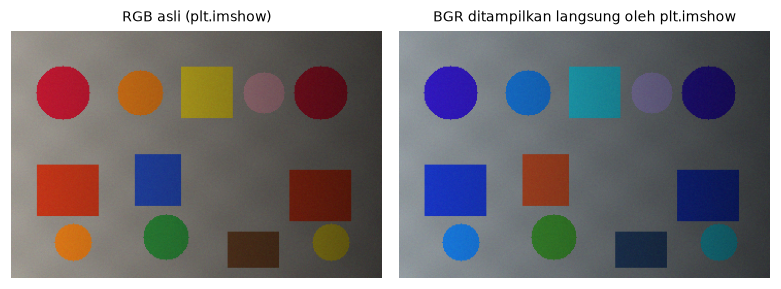

objek[60, 50] RGB = [181  22  47] | versi BGR = [ 47  22 181]


In [2]:
# TODO 0.1 — Jebakan BGR. cv2.imread menghasilkan urutan B, G, R. Tirukan dengan cv2.cvtColor(objek, cv2.COLOR_RGB2BGR),
#            tampilkan hasilnya LANGSUNG dengan plt.imshow, lalu cetak nilai piksel objek[60, 50] dan versi BGR-nya.
bgr = cv2.cvtColor(objek, cv2.COLOR_RGB2BGR)
tampil([objek, bgr], ['RGB asli (plt.imshow)', 'BGR ditampilkan langsung oleh plt.imshow'])
print('objek[60, 50] RGB =', objek[60, 50], '| versi BGR =', bgr[60, 50])


## Bagian 1 &mdash; Konversi dari definisi (25 menit)

**HSI menurut Gonzalez** (RGB dinormalisasi ke [0, 1]):

$$\theta = \cos^{-1}\left\{\frac{\tfrac12[(R-G)+(R-B)]}{[(R-G)^2+(R-B)(G-B)]^{1/2}}\right\},\quad H = \begin{cases}\theta & B \le G\\ 360-\theta & B > G\end{cases}\quad \text{(6-16, 6-17)}$$

$$S = 1 - \frac{3}{R+G+B}\min(R,G,B) \quad\text{(6-18)},\qquad I = \tfrac13(R+G+B)\quad\text{(6-19)}$$

Kebalikannya dihitung per sektor 120&deg; (Eq. 6-20 s.d. 6-30). Pada sektor RG (0 &le; H &lt; 120&deg;): $B = I(1-S)$, $R = I[1 + S\cos H/\cos(60^\circ - H)]$, $G = 3I - (R+B)$.
Sektor GB dan BR memakai rumus yang sama setelah H dikurangi 120&deg; atau 240&deg;, dengan peran R, G, B digeser.

**HSV (Smith, 1978; dipakai OpenCV)**: $V = \max(R,G,B)$, $S = (V - \min)/V$, H dihitung per sektor 60&deg;. Pada citra 8-bit OpenCV menyimpan **H/2** (0&ndash;179), S&times;255, V&times;255.

In [3]:
# TODO 1.1 — Implementasikan rgb_ke_hsi dari Eq. 6-16 s.d. 6-19. Masukan uint8 atau float [0, 1]; keluaran H (derajat), S, I.
#            Tambahkan bilangan kecil pada penyebut (catatan kaki Gonzalez) dan set H = 0 bila S = 0.
def rgb_ke_hsi(rgb):
    rgb = np.asarray(rgb, dtype=float)
    if rgb.max() > 1.0:
        rgb = rgb / 255.0
    r, g, b = rgb[..., 0], rgb[..., 1], rgb[..., 2]
    jumlah = r + g + b
    num = 0.5 * ((r - g) + (r - b))
    den = np.sqrt((r - g) ** 2 + (r - b) * (g - b)) + 1e-8
    theta = np.degrees(np.arccos(np.clip(num / den, -1.0, 1.0)))
    H = np.where(b <= g, theta, 360.0 - theta)
    S = np.where(jumlah > 1e-8, 1.0 - 3.0 * np.minimum(np.minimum(r, g), b) / (jumlah + 1e-8), 0.0)
    I = jumlah / 3.0
    H = np.where(S < 1e-8, 0.0, H)
    return H, S, I

H, S, I = rgb_ke_hsi(np.array([[[0.8, 0.5, 0.2]]]))
print('HSI (0.8, 0.5, 0.2):', H[0, 0], S[0, 0], I[0, 0])


HSI (0.8, 0.5, 0.2): 30.000001909859236 0.6000000026666665 0.5


In [4]:
# TODO 1.2 — Implementasikan hsi_ke_rgb (Eq. 6-20 s.d. 6-30) untuk ketiga sektor.
#            Uji: konversi `objek` ke HSI lalu kembali; laporkan selisih maksimum (skala 0..1).
def hsi_ke_rgb(H, S, I):
    H, S, I = np.asarray(H, float), np.asarray(S, float), np.asarray(I, float)
    h = np.mod(H, 360.0)
    sektor = np.floor(h / 120.0)
    hs = np.radians(h - 120.0 * sektor)
    Bp = I * (1.0 - S)
    Rp = I * (1.0 + S * np.cos(hs) / np.cos(np.radians(60.0) - hs))
    Gp = 3.0 * I - (Rp + Bp)
    R = np.where(sektor == 0, Rp, np.where(sektor == 1, Bp, Gp))
    G = np.where(sektor == 0, Gp, np.where(sektor == 1, Rp, Bp))
    B = np.where(sektor == 0, Bp, np.where(sektor == 1, Gp, Rp))
    return np.stack([R, G, B], axis=-1)

H, S, I = rgb_ke_hsi(objek)
kembali = hsi_ke_rgb(H, S, I)
selisih = np.abs(kembali - objek / 255.0)
print(f'Selisih maksimum HSI bolak-balik (skala 0..1): {selisih.max():.3e}')
print(f'Rerata selisih HSI bolak-balik: {selisih.mean():.3e}')


Selisih maksimum HSI bolak-balik (skala 0..1): 8.911e-05
Rerata selisih HSI bolak-balik: 4.998e-07


In [5]:
# TODO 1.3 — Implementasikan rgb_ke_hsv (heksakerucut). Bandingkan dengan cv2.cvtColor(objek, cv2.COLOR_RGB2HSV):
#            ingat OpenCV 8-bit menyimpan H/2 dan S×255. Laporkan selisih hue maksimum (derajat) dan penyebabnya.
#            Lalu cetak piksel (204, 128, 51) dalam tiga bentuk: HSI Anda, HSV Anda, dan HSV 8-bit OpenCV.
def rgb_ke_hsv(rgb):
    rgb = np.asarray(rgb, dtype=float)
    if rgb.max() > 1.0:
        rgb = rgb / 255.0
    r, g, b = rgb[..., 0], rgb[..., 1], rgb[..., 2]
    mx = np.maximum(np.maximum(r, g), b)
    mn = np.minimum(np.minimum(r, g), b)
    d = mx - mn
    H = np.zeros_like(mx)
    aman = d > 1e-12
    idx = aman & (mx == r)
    H[idx] = (60.0 * ((g[idx] - b[idx]) / d[idx])) % 360.0
    idx = aman & (mx == g) & ~(mx == r)
    H[idx] = 60.0 * ((b[idx] - r[idx]) / d[idx] + 2.0)
    idx = aman & (mx == b) & ~(mx == r) & ~(mx == g)
    H[idx] = 60.0 * ((r[idx] - g[idx]) / d[idx] + 4.0)
    S = np.where(mx > 1e-12, d / np.maximum(mx, 1e-12), 0.0)
    return H, S, mx

p = np.array([[[204, 128, 51]]], dtype=np.uint8)
Hp, Sp, Ip = rgb_ke_hsi(p)
Hv, Sv, Vv = rgb_ke_hsv(p)
Hcv, Scv, Vcv = cv2.cvtColor(p, cv2.COLOR_RGB2HSV)[0, 0]
print(f'Piksel (204,128,51): HSI H={Hp[0,0]:.2f}°, S={Sp[0,0]:.4f}, I={Ip[0,0]:.4f}')
print(f'HSV sendiri: H={Hv[0,0]:.2f}°, S={Sv[0,0]:.4f}, V={Vv[0,0]:.4f}')
print(f'HSV OpenCV 8-bit: H={Hcv} (={Hcv*2:.0f}°), S={Scv} (={Scv/255:.4f}), V={Vcv} (={Vcv/255:.4f})')
Hc, Sc, Vc = rgb_ke_hsv(objek)
hsv_cv = cv2.cvtColor(objek, cv2.COLOR_RGB2HSV)
d_hue = beda_hue(Hc, hsv_cv[..., 0].astype(float) * 2.0)
print(f'Selisih hue maksimum vs OpenCV: {d_hue.max():.3f}°; rerata: {d_hue.mean():.3f}°')
print(f'Selisih S maksimum vs OpenCV/255: {np.abs(Sc - hsv_cv[..., 1] / 255.0).max():.4f}')


Piksel (204,128,51): HSI H=30.22°, S=0.6005, I=0.5007
HSV sendiri: H=30.20°, S=0.7500, V=0.8000
HSV OpenCV 8-bit: H=15 (=30°), S=191 (=0.7490), V=204 (=0.8000)
Selisih hue maksimum vs OpenCV: 1.043°; rerata: 0.369°
Selisih S maksimum vs OpenCV/255: 0.0020


In [6]:
# TODO 1.4 — Lab. (a) Hitung cv2.cvtColor(p, cv2.COLOR_RGB2Lab) untuk p = (204, 128, 51) dan kembalikan ke L*, a*, b* sebenarnya
#            (OpenCV 8-bit: L×255/100, a+128, b+128). (b) Bandingkan dengan skimage.color.rgb2lab(p).
#            (c) Mengapa jarak Euclid pada keluaran 8-bit OpenCV BUKAN ΔE*ab? Tunjukkan dengan dua warna yang hanya berbeda L*.
def lab8_ke_lab(lab8):
    lab8 = np.asarray(lab8, float)
    return np.stack([lab8[..., 0] * 100.0 / 255.0, lab8[..., 1] - 128.0, lab8[..., 2] - 128.0], axis=-1)

p = np.array([[[204, 128, 51]]], dtype=np.uint8)
lab8 = cv2.cvtColor(p, cv2.COLOR_RGB2Lab)
lab_cv = lab8_ke_lab(lab8)[0, 0]
lab_sk = color.rgb2lab(p / 255.0)[0, 0]
print(f'OpenCV 8-bit mentah: {lab8[0, 0]} -> L*={lab_cv[0]:.3f}, a*={lab_cv[1]:.3f}, b*={lab_cv[2]:.3f}')
print(f'skimage rgb2lab: L*={lab_sk[0]:.3f}, a*={lab_sk[1]:.3f}, b*={lab_sk[2]:.3f}')
print(f'Selisih OpenCV vs skimage: {np.abs(lab_cv - lab_sk).max():.3f}')
g1 = np.array([[[100, 100, 100]]], dtype=np.uint8)
g2 = np.array([[[110, 110, 110]]], dtype=np.uint8)
l1 = lab8_ke_lab(cv2.cvtColor(g1, cv2.COLOR_RGB2Lab))[0, 0]
l2 = lab8_ke_lab(cv2.cvtColor(g2, cv2.COLOR_RGB2Lab))[0, 0]
d8 = np.linalg.norm(cv2.cvtColor(g1, cv2.COLOR_RGB2Lab).astype(float) - cv2.cvtColor(g2, cv2.COLOR_RGB2Lab).astype(float))
d_true = np.linalg.norm(l1 - l2)
print(f'Dua abu-abu beda L*: ΔE*ab sebenarnya={d_true:.3f}, jarak Euclid 8-bit={d8:.3f}, nisbah={d8/d_true:.3f}')


OpenCV 8-bit mentah: [154 151 180] -> L*=60.392, a*=23.000, b*=52.000
skimage rgb2lab: L*=60.354, a*=23.093, b*=51.961
Selisih OpenCV vs skimage: 0.093
Dua abu-abu beda L*: ΔE*ab sebenarnya=4.314, jarak Euclid 8-bit=11.000, nisbah=2.550


In [7]:
# [Pengayaan] TODO 1.5 — Implementasikan Lab dari definisi (Eq. 6-31 s.d. 6-34) dengan linearisasi sRGB dan matriks sRGB→XYZ (D65).
#            Bandingkan dengan skimage; lalu ulangi TANPA linearisasi. Berapa selisih maksimumnya? Apa artinya bagi rumus di dokumentasi?


**Analisis 1.** (a) Tuliskan nilai HSI, HSV, dan HSV 8-bit OpenCV untuk piksel (204, 128, 51). Mengapa S berbeda antara HSI dan HSV padahal H sama? (b) Dari mana selisih hue &asymp;1&deg; antara implementasi Anda dan OpenCV? (c) Apa akibatnya bila ambang Lab dirancang dari literatur (L* 0&ndash;100) tetapi diterapkan pada keluaran 8-bit OpenCV?

*Jawaban:* (a) Untuk piksel `(204,128,51)`, HSI menghasilkan `H=30.22°`, `S=0.6005`, `I=0.5007`. HSV menghasilkan `H=30.20°`, `S=0.7500`, `V=0.8000`, sedangkan OpenCV memberi `H=15` atau `30°`, `S=191` atau `0.7490`, dan `V=204` atau `0.8000`. Hue hampir sama karena sama-sama menunjukkan jenis warna, tetapi nilai S berbeda karena HSI membandingkan warna dengan jumlah seluruh kanal, sedangkan HSV membandingkannya dengan kanal paling terang. (b) Selisih hue maksimum hanya `1.043°`, terutama karena OpenCV menyimpan hue dalam bentuk bilangan bulat dengan ketelitian 2°. (c) Nilai L* dari buku memakai skala `0–100`, sedangkan OpenCV memakai `0–255`. Jadi L* `60.392` tersimpan sebagai `154`; ambang dari buku harus dikalikan `2.55` sebelum dipakai pada hasil OpenCV. Jarak warna juga berubah: `ΔE*ab=4.314`, tetapi jarak pada skala 8-bit menjadi `11.000`. 

## Bagian 2 &mdash; Pencahayaan dan derau (20 menit)

Citra `objek` memuat dua cakram **berwarna sama** (merah tua): satu di sisi terang (pusat baris 60, kolom 50; faktor cahaya 0,91) dan satu di sisi gelap (kolom 300; faktor 0,46).

In [8]:
# TODO 2.1 — Untuk cakram kiri dan kanan (jari-jari 20 piksel), hitung rerata R, G, B; H, S, V (HSV Anda); H, S, I (HSI);
#            L*, a*, b*, kroma C* = sqrt(a*² + b*²), dan sudut hue h_ab = atan2(b*, a*). Pakai rerata_hue untuk sudut.
#            Susun tabel: kiri, kanan, dan nisbah kanan/kiri (untuk sudut: selisih derajat).
kiri = (YY - 60) ** 2 + (XX - 50) ** 2 <= 20 ** 2
kanan = (YY - 60) ** 2 + (XX - 300) ** 2 <= 20 ** 2

def ringkas_warna(mask):
    px = objek[mask].astype(float) / 255.0
    Hh, Sh, Vh = rgb_ke_hsv(px)
    Hi, Si, Ii = rgb_ke_hsi(px)
    lab = color.rgb2lab(px)
    a, b = lab[:, 1], lab[:, 2]
    return {'R': px[:, 0].mean(), 'G': px[:, 1].mean(), 'B': px[:, 2].mean(),
            'H_HSV': rerata_hue(Hh), 'S_HSV': Sh.mean(), 'V': Vh.mean(),
            'H_HSI': rerata_hue(Hi), 'S_HSI': Si.mean(), 'I': Ii.mean(),
            'L*': lab[:, 0].mean(), 'a*': a.mean(), 'b*': b.mean(),
            'C*': np.hypot(a.mean(), b.mean()),
            'h_ab': rerata_hue(np.degrees(np.arctan2(b, a)))}

k = ringkas_warna(kiri)
kn = ringkas_warna(kanan)
print(f"{'besaran':>8s} {'kiri':>9s} {'kanan':>9s} {'kanan/kiri':>12s}")
for nama in k:
    if nama.startswith('H') or nama == 'h_ab':
        print(f"{nama:>8s} {k[nama]:9.2f} {kn[nama]:9.2f} {beda_hue(k[nama], kn[nama]):12.2f}")
    else:
        print(f"{nama:>8s} {k[nama]:9.3f} {kn[nama]:9.3f} {kn[nama] / k[nama]:12.3f}")
print(f"Nisbah V={kn['V']/k['V']:.3f}, I={kn['I']/k['I']:.3f}, L*={kn['L*']/k['L*']:.3f}; "
      f"Δh_HSV={beda_hue(k['H_HSV'], kn['H_HSV']):.2f}°, Δh_ab={beda_hue(k['h_ab'], kn['h_ab']):.2f}°")
print(f"a*: {k['a*']:.3f} -> {kn['a*']:.3f} (nisbah {kn['a*']/k['a*']:.3f}); "
      f"b*: {k['b*']:.3f} -> {kn['b*']:.3f} (nisbah {kn['b*']/k['b*']:.3f})")


 besaran      kiri     kanan   kanan/kiri
       R     0.710     0.357        0.503
       G     0.091     0.045        0.498
       B     0.182     0.091        0.502
   H_HSV    351.22    351.20         0.02
   S_HSV     0.871     0.872        1.001
       V     0.710     0.357        0.503
   H_HSI    352.21    352.15         0.05
   S_HSI     0.721     0.724        1.004
       I     0.328     0.165        0.502
      L*    38.983    18.111        0.465
      a*    59.706    35.155        0.589
      b*    30.400    15.888        0.523
      C*    67.000    38.579        0.576
    h_ab     26.97     24.27         2.70
Nisbah V=0.503, I=0.502, L*=0.465; Δh_HSV=0.02°, Δh_ab=2.70°
a*: 59.706 -> 35.155 (nisbah 0.589); b*: 30.400 -> 15.888 (nisbah 0.523)


In [9]:
# TODO 2.2 — Kapan hue tidak bisa dipercaya? Bangkitkan 20000 piksel ber-hue 20° dengan S dan V tertentu,
#            tambahkan derau Gaussian σ = 3 aras per kanal, hitung simpangan baku melingkar hue (std_melingkar).
#            Lakukan untuk S ∈ {0.05, 0.1, 0.2, 0.4, 0.8} (V = 0.8), lalu V ∈ {0.05, 0.1, 0.2, 0.4, 0.8} (S = 0.8).
rng = np.random.default_rng(7)      # jangan diubah agar angka sebanding
def piksel_uji(sat, val, n=20000, sigma=3.0):
    dasar = np.array([1.0, 1 - sat * (1 - 20 / 60), 1 - sat]) * val
    return np.clip(np.floor(dasar * 255 + rng.normal(0, sigma, (n, 3)) + 0.5), 0, 255).astype(np.uint8)[None]

def uji_hue(sat, val):
    h, _, _ = rgb_ke_hsv(piksel_uji(sat, val))
    return std_melingkar(h)

S_uji = [0.05, 0.1, 0.2, 0.4, 0.8]
V_uji = [0.05, 0.1, 0.2, 0.4, 0.8]
sd_S = [uji_hue(s, 0.8) for s in S_uji]
sd_V = [uji_hue(0.8, v) for v in V_uji]
print('S      sigma_hue (V=0.8)')
for s, sd in zip(S_uji, sd_S):
    print(f'{s:5.2f}  {sd:8.2f}')
print('V      sigma_hue (S=0.8)')
for v, sd in zip(V_uji, sd_V):
    print(f'{v:5.2f}  {sd:8.2f}')
aman_S = next((s for s, sd in zip(S_uji, sd_S) if sd <= 10), None)
aman_V = next((v for v, sd in zip(V_uji, sd_V) if sd <= 10), None)
print(f'Ambang aman (sigma <= 10°): S >= {aman_S}, V >= {aman_V}')


S      sigma_hue (V=0.8)
 0.05     26.18
 0.10     11.82
 0.20      5.66
 0.40      2.81
 0.80      1.38
V      sigma_hue (S=0.8)
 0.05     26.31
 0.10     11.60
 0.20      5.63
 0.40      2.78
 0.80      1.38
Ambang aman (sigma <= 10°): S >= 0.2, V >= 0.2


**Analisis 2.** (a) Besaran mana yang **tetap** (nisbah &asymp; 1 atau selisih &asymp; 0&deg;) dan mana yang ikut turun &asymp;50 %? Apakah a* dan b* termasuk yang tetap? (b) Pada S atau V berapa simpangan baku hue melebihi 10&deg;? Mengapa S dan V memberi angka hampir sama (petunjuk: penyebut rumus hue adalah maks &minus; min)? (c) Rumuskan syarat praktis sebelum Anda memakai ambang hue.

*Jawaban:* (a) Ketika cahaya turun, nilai merah, hijau, biru, V, I, dan L* ikut turun sekitar setengahnya. Contohnya, nilai R berubah dari `0.710` menjadi `0.357`, dengan nisbah `0.503`. Sebaliknya, jenis warna hampir tetap: hue HSV hanya berubah `0.02°`, dan saturasi HSV memiliki nisbah `1.001`. Nilai a* dan b* tidak sepenuhnya tetap; a* berubah dari `59.706` menjadi `35.155`, sedangkan b* dari `30.400` menjadi `15.888`. (b) Hue mulai tidak stabil saat S atau V berada di `0.10` atau lebih rendah. Simpangan hue mencapai `26.18°` pada `S=0.05` dan `26.31°` pada `V=0.05`. Artinya, warna yang sangat pucat atau sangat gelap mudah salah dibaca ketika ada derau. (c) Sebelum memakai hue, pastikan objek cukup berwarna dan cukup terang. Pada percobaan ini syarat amannya sekitar `S>=0.2` dan `V>=0.2`; jika kurang, gunakan informasi warna lain juga.

## Bagian 3 &mdash; Pemrosesan citra berwarna (20 menit)

Gonzalez (§6.5) memperingatkan bahwa ekualisasi histogram setiap kanal RGB secara terpisah menghasilkan warna keliru; yang masuk akal adalah meratakan **intensitas** dan membiarkan hue. Kita ukur.

cara                     Δhue(°)  rerata I  rerata S
(a) RGB per kanal          67.54    0.4629    0.3153
(b) kanal I HSI             6.18    0.4423    0.7446
(c) kanal V HSV             0.52    0.2702    0.7843
(d) kanal L* Lab            2.78    0.4488    0.3500


Piksel (b) di luar [0,1] sebelum clip: 59.55%
Acuan redup: rerata I=0.2163, rerata S=0.7773


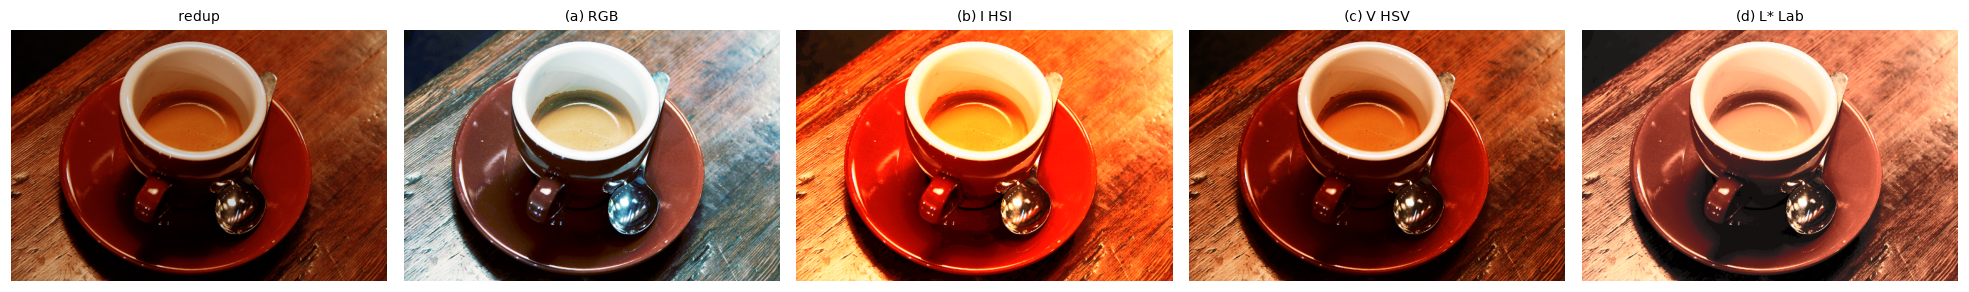

In [10]:
# TODO 3.1 — Buat citra redup: redup = 0.85 · (kopi/255)^1.8 (bulatkan ke uint8). Lakukan ekualisasi histogram dengan empat cara:
#   (a) setiap kanal RGB terpisah; (b) kanal I (HSI Anda), kembalikan dengan hsi_ke_rgb lalu clip;
#   (c) kanal V dari cv2 HSV; (d) kanal L* dari Lab (pakai skimage rgb2lab/lab2rgb, L* diskala ke 0..255 untuk equalizeHist).
# Ukur terhadap `redup`: rerata pergeseran hue (beda_hue, hanya piksel S > 0,2 dan V > 0,08), rerata I, rerata S,
# dan untuk (b) persentase piksel yang keluar dari [0, 1] sebelum clip.
redup = np.clip(np.floor(255 * 0.85 * (kopi / 255.0) ** 1.8 + 0.5), 0, 255).astype(np.uint8)

H_acuan, S_acuan, V_acuan = rgb_ke_hsv(redup)
valid = (S_acuan > 0.2) & (V_acuan > 0.08)

def ukur_eq(nama, im):
    Hx, Sx, Vx = rgb_ke_hsv(im)
    _, Si, Ii = rgb_ke_hsi(im)
    return {'nama': nama, 'dhue': float(beda_hue(H_acuan[valid], Hx[valid]).mean()),
            'I': float(Ii.mean()), 'S': float(Si.mean())}

eq_rgb = np.stack([cv2.equalizeHist(redup[..., i]) for i in range(3)], axis=-1)
Hi, Si, Ii = rgb_ke_hsi(redup)
I8 = np.clip(np.floor(Ii * 255 + 0.5), 0, 255).astype(np.uint8)
Ieq = cv2.equalizeHist(I8).astype(float) / 255.0
rgb_i_float = hsi_ke_rgb(Hi, Si, Ieq)
luar = np.any((rgb_i_float < 0) | (rgb_i_float > 1), axis=-1)
eq_i = np.clip(np.floor(rgb_i_float * 255 + 0.5), 0, 255).astype(np.uint8)
hsv_r = cv2.cvtColor(redup, cv2.COLOR_RGB2HSV)
hsv_v = hsv_r.copy()
hsv_v[..., 2] = cv2.equalizeHist(hsv_r[..., 2])
eq_v = cv2.cvtColor(hsv_v, cv2.COLOR_HSV2RGB)
lab = color.rgb2lab(redup / 255.0)
L8 = np.clip(np.floor(lab[..., 0] * 255.0 / 100.0 + 0.5), 0, 255).astype(np.uint8)
lab_l = lab.copy()
lab_l[..., 0] = cv2.equalizeHist(L8).astype(float) * 100.0 / 255.0
eq_l = np.clip(np.floor(color.lab2rgb(lab_l) * 255 + 0.5), 0, 255).astype(np.uint8)
metrik3 = [ukur_eq('(a) RGB per kanal', eq_rgb), ukur_eq('(b) kanal I HSI', eq_i),
           ukur_eq('(c) kanal V HSV', eq_v), ukur_eq('(d) kanal L* Lab', eq_l)]
print(f"{'cara':22s} {'Δhue(°)':>9s} {'rerata I':>9s} {'rerata S':>9s}")
for m in metrik3:
    print(f"{m['nama']:22s} {m['dhue']:9.2f} {m['I']:9.4f} {m['S']:9.4f}")
print(f"Piksel (b) di luar [0,1] sebelum clip: {100.0 * luar.mean():.2f}%")
print(f"Acuan redup: rerata I={Ii.mean():.4f}, rerata S={Si.mean():.4f}")
tampil([redup, eq_rgb, eq_i, eq_v, eq_l],
       ['redup', '(a) RGB', '(b) I HSI', '(c) V HSV', '(d) L* Lab'], kolom=5)


In [11]:
# [Pengayaan] TODO 3.2 — Subsampling krominans. Ubah kopi ke YCbCr (cv2.COLOR_RGB2YCrCb — perhatikan urutan Y, Cr, Cb!),
#            perkecil Cr dan Cb 2× dan 4× (cv2.resize INTER_AREA, lalu perbesar INTER_LINEAR), kembalikan ke RGB, hitung PSNR.
#            Bandingkan dengan memperkecil R, G, B sama besar sehingga jumlah data sama (faktor per sumbu √(3/(1 + 2/f²))).


**Analisis 3.** (a) Cara mana yang paling merusak hue, dan mengapa? (b) Mengapa ekualisasi kanal I menghasilkan banyak piksel di luar gamut, dan apa akibat pemotongan (clip) terhadap hue? (c) Ekualisasi V menjaga hue hampir sempurna tetapi kecerahannya naik paling sedikit. Jelaskan dari definisi V. (d) Tidak ada cara yang menang di semua ukuran. Mana yang Anda pilih untuk citra kamera kapal yang redup, dan apa harganya?

*Jawaban:* (a) Cara yang paling mengubah warna adalah pemerataan tiap kanal RGB. Pergeseran hue mencapai `67.54°`, sedangkan kanal V HSV hanya `0.52°` dan kanal L* Lab `2.78°`. Penyebabnya, merah, hijau, dan biru diubah dengan cara berbeda sehingga warna asli ikut berubah. (b) Pada pemerataan kanal I HSI, sebanyak `59.55%` piksel menghasilkan warna yang tidak dapat ditampilkan secara normal. Saat nilainya dipotong ke rentang `0–1`, warna ikut bergeser; pergeseran hue tercatat `6.18°`. (c) V HSV adalah nilai kanal paling terang. Ketika hanya V yang diratakan, perbandingan antar-kanal tetap hampir sama, sehingga hue hampir tidak berubah. Pergeseran hue hanya `0.52°`, tetapi rata-rata I naik dari `0.2163` menjadi `0.2702`. (d) Untuk kamera kapal yang redup, V HSV lebih aman jika warna objek harus dipertahankan. Jika gambar perlu dibuat jauh lebih terang, L* Lab bisa dipilih, tetapi pergeseran warnanya lebih besar, yaitu `2.78°`.

## Bagian 4 &mdash; Segmentasi berbasis warna (30 menit)

Tugas: temukan keempat objek merah pada `objek` (dua merah tua, hue &asymp;351&deg;; dua merah bata, hue &asymp;10&deg;). **Sampel latih hanya boleh diambil dari sisi terang** (kolom &lt; 120), kecuali bila diminta lain. Penilaian memakai `gt_merah` dan fungsi `nilai`.

Jarak Euclid (Eq. 6-48): $D(\mathbf z, \mathbf a) = \lVert \mathbf z - \mathbf a\rVert$. Jarak Mahalanobis (Eq. 6-49): $D(\mathbf z, \mathbf a) = [(\mathbf z - \mathbf a)^T \mathbf C^{-1}(\mathbf z - \mathbf a)]^{1/2}$. Ambang $D_0$ = persentil 99 jarak sampel latih ke reratanya.

In [12]:
# TODO 4.1 — Aturan RGB tetap dari contoh Blok 1: R > 150, G < 80, B < 80. Nilai dengan nilai(pred, gt_merah).
latih = gt_merah & (XX < 120)
f = objek.reshape(-1, 3).astype(float)
hasil = {}
masker = {}

pred_rgb = (objek[..., 0] > 150) & (objek[..., 1] < 80) & (objek[..., 2] < 80)
nama = 'RGB tetap (R>150,G<80,B<80)'
masker[nama] = pred_rgb
hasil[nama] = nilai(pred_rgb, gt_merah)
print(f'{nama}: {hasil[nama]}')


RGB tetap (R>150,G<80,B<80): {'iou': 0.5, 'presisi': 1.0, 'recall': 0.5, 'komponen': 2}


In [13]:
# TODO 4.2 — (a) Bola Euclid (Eq. 6-48) dan (b) elipsoid Mahalanobis (Eq. 6-49) dari sampel `latih`.
#            (c) Ulangi Mahalanobis dengan sampel latih ditambah cakram merah tua sisi gelap (pusat 60, 300; r = 20).
def euclid(fitur, sampel):
    fitur, sampel = np.asarray(fitur, float), np.asarray(sampel, float)
    a = sampel.mean(axis=0)
    D = np.linalg.norm(fitur - a, axis=1)
    D0 = np.percentile(np.linalg.norm(sampel - a, axis=1), 99)
    return D, float(D0)

def mahalanobis(fitur, sampel):
    fitur, sampel = np.asarray(fitur, float), np.asarray(sampel, float)
    a = sampel.mean(axis=0)
    Cm = np.cov(sampel, rowvar=False) + 1e-6 * np.eye(sampel.shape[1])
    Ci = np.linalg.inv(Cm)
    def jarak(x):
        d = x - a
        return np.sqrt(np.einsum('ij,jk,ik->i', d, Ci, d))
    return jarak(fitur), float(np.percentile(jarak(sampel), 99))

sampel = f[latih.ravel()]
D_e, D0_e = euclid(f, sampel)
nama = 'Euclid RGB'
masker[nama] = (D_e <= D0_e).reshape(objek.shape[:2])
hasil[nama] = nilai(masker[nama], gt_merah)
print(f'{nama}: {hasil[nama]} (D0={D0_e:.2f})')
D_m, D0_m = mahalanobis(f, sampel)
nama = 'Mahalanobis RGB'
masker[nama] = (D_m <= D0_m).reshape(objek.shape[:2])
hasil[nama] = nilai(masker[nama], gt_merah)
print(f'{nama}: {hasil[nama]} (D0={D0_m:.2f})')
gelap = (YY - 60) ** 2 + (XX - 300) ** 2 <= 20 ** 2
sampel_gelap = np.vstack([sampel, f[gelap.ravel()]])
D_mg, D0_mg = mahalanobis(f, sampel_gelap)
nama = 'Mahalanobis RGB + gelap'
masker[nama] = (D_mg <= D0_mg).reshape(objek.shape[:2])
hasil[nama] = nilai(masker[nama], gt_merah)
print(f'{nama}: {hasil[nama]} (D0={D0_mg:.2f})')


Euclid RGB: {'iou': 0.495, 'presisi': 1.0, 'recall': 0.495, 'komponen': 2} (D0=27.19)
Mahalanobis RGB: {'iou': 0.495, 'presisi': 1.0, 'recall': 0.495, 'komponen': 2} (D0=3.02)
Mahalanobis RGB + gelap: {'iou': 0.978, 'presisi': 1.0, 'recall': 0.978, 'komponen': 4} (D0=3.02)


In [14]:
# TODO 4.3 — HSV OpenCV 8-bit. Syarat dasar S ≥ 120 dan V ≥ 40. Bandingkan:
#            (a) satu selang H ≤ 10; (b) dua selang H ≤ 10 atau H ≥ 170; (c) dua selang tanpa syarat S.
hv = cv2.cvtColor(objek, cv2.COLOR_RGB2HSV).astype(int)
H8, S8, V8 = hv[..., 0], hv[..., 1], hv[..., 2]
dasar = (S8 >= 120) & (V8 >= 40)

nama = 'HSV satu selang H<=10'
masker[nama] = dasar & (H8 <= 10)
hasil[nama] = nilai(masker[nama], gt_merah)
print(f'{nama}: {hasil[nama]}')
nama = 'HSV dua selang (S>=120,V>=40)'
masker[nama] = dasar & ((H8 <= 10) | (H8 >= 170))
hasil[nama] = nilai(masker[nama], gt_merah)
print(f'{nama}: {hasil[nama]}')
nama = 'HSV dua selang tanpa S'
masker[nama] = ((H8 <= 10) | (H8 >= 170)) & (V8 >= 40)
hasil[nama] = nilai(masker[nama], gt_merah)
print(f'{nama}: {hasil[nama]}')


HSV satu selang H<=10: {'iou': 0.569, 'presisi': 0.948, 'recall': 0.587, 'komponen': 141}
HSV dua selang (S>=120,V>=40): {'iou': 0.969, 'presisi': 0.969, 'recall': 1.0, 'komponen': 133}
HSV dua selang tanpa S: {'iou': 0.397, 'presisi': 0.397, 'recall': 1.0, 'komponen': 4373}


metode                            IoU  presisi  recall  komponen
Lab selang hue + C*             0.995    1.000   0.995         4
Mahalanobis RGB + gelap         0.978    1.000   0.978         4
HSV dua selang (S>=120,V>=40)   0.969    0.969   1.000       133
HSV satu selang H<=10           0.569    0.948   0.587       141
RGB tetap (R>150,G<80,B<80)     0.500    1.000   0.500         2
Euclid RGB                      0.495    1.000   0.495         2
Mahalanobis RGB                 0.495    1.000   0.495         2
Lab Euclid a*b*                 0.495    1.000   0.495         2
HSV dua selang tanpa S          0.397    0.397   1.000      4373
Terbaik: Lab selang hue + C* (IoU=0.995); terburuk: HSV dua selang tanpa S (IoU=0.397)


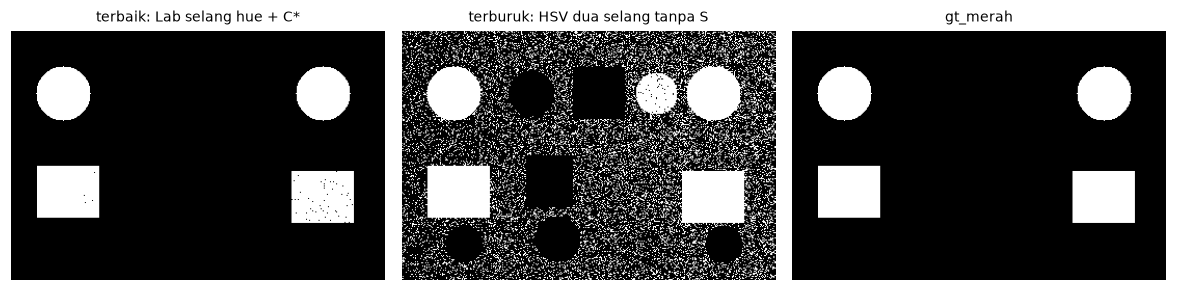

In [15]:
# TODO 4.4 — Lab. (a) Bola Euclid pada bidang a*b* saja (L* diabaikan), sampel `latih`.
#            (b) Selang sudut hue h_ab ≤ 45° atau ≥ 345° dengan kroma C* ≥ 25.
#            Lalu cetak seluruh `hasil` sebagai satu tabel dan tampilkan masker terbaik serta terburuk.
lab_obj = color.rgb2lab(objek / 255.0)
a_lab, b_lab = lab_obj[..., 1], lab_obj[..., 2]
fit_lab = np.column_stack([a_lab.ravel(), b_lab.ravel()])
sampel_lab = np.column_stack([a_lab[latih], b_lab[latih]])
D_lab, D0_lab = euclid(fit_lab, sampel_lab)
nama = 'Lab Euclid a*b*'
masker[nama] = (D_lab <= D0_lab).reshape(objek.shape[:2])
hasil[nama] = nilai(masker[nama], gt_merah)
h_ab = np.degrees(np.arctan2(b_lab, a_lab)) % 360.0
C_star = np.hypot(a_lab, b_lab)
nama = 'Lab selang hue + C*'
masker[nama] = ((h_ab <= 45) | (h_ab >= 345)) & (C_star >= 25)
hasil[nama] = nilai(masker[nama], gt_merah)
print(f"{'metode':30s} {'IoU':>6s} {'presisi':>8s} {'recall':>7s} {'komponen':>9s}")
for nama, m in sorted(hasil.items(), key=lambda kv: -kv[1]['iou']):
    print(f"{nama:30s} {m['iou']:6.3f} {m['presisi']:8.3f} {m['recall']:7.3f} {m['komponen']:9d}")
terbaik = max(hasil, key=lambda n: hasil[n]['iou'])
terburuk = min(hasil, key=lambda n: hasil[n]['iou'])
print(f"Terbaik: {terbaik} (IoU={hasil[terbaik]['iou']:.3f}); terburuk: {terburuk} (IoU={hasil[terburuk]['iou']:.3f})")
tampil([masker[terbaik], masker[terburuk], gt_merah],
       [f'terbaik: {terbaik}', f'terburuk: {terburuk}', 'gt_merah'], kolom=3, cmap='gray')


**Analisis 4.** (a) Gonzalez (§6.7) menyatakan segmentasi pada vektor RGB *umumnya* lebih baik daripada HSI, sedangkan banyak tutorial menyatakan sebaliknya. Dengan angka TODO 4.2 dan 4.3, tunjukkan kapan masing-masing benar. (b) Mengapa jarak Euclid pada a*b* gagal sama parahnya dengan RGB, padahal Lab "memisahkan kecerahan"? (c) Mengapa HSV dua selang memberi puluhan komponen walau IoU-nya tinggi, dan dari objek mana komponen palsu itu? (d) Sebutkan satu prasyarat agar jumlah komponen dapat dipakai sebagai ukuran.

*Jawaban:* (a) Metode RGB hanya mendapat IoU `0.500` karena objek merah yang gelap tidak ikut terdeteksi. HSV dua selang mendapat `0.969`, sedangkan Lab hue+C* mendapat `0.995`. Jadi HSV dan Lab lebih cocok pada contoh ini karena jenis warna lebih tahan terhadap perubahan terang-gelap. (b) Jarak a*b* tetap gagal dengan IoU `0.495`. Walaupun L* memisahkan terang-gelap, a* berubah dari `59.706` menjadi `35.155`, dan b* dari `30.400` menjadi `15.888`. (c) HSV memiliki IoU tinggi `0.969`, tetapi menghasilkan `133` bagian kecil karena objek cokelat ikut terbaca sebagai merah. (d) Jumlah bagian baru dapat dipercaya jika derau dibersihkan dan setiap objek diharapkan menjadi satu bagian utuh. Jadi klaim RGB "umumnya lebih baik" berlaku bila variasi cahaya kecil dan kelas RGB terpisah; klaim HSV lebih baik berlaku di sini karena hue stabil terhadap iluminasi. (b) Euclid pada a*b* juga gagal (IoU `0.495`) karena bidang a*b* tetap berubah skala saat cahaya berubah: a* turun `59.706→35.155` (nisbah `0.589`) dan b* `30.400→15.888` (`0.523`); "memisahkan kecerahan" tidak berarti invarian terhadap intensitas. (c) HSV dua selang ber-IoU `0.969` tetapi `133` komponen karena selain empat objek merah, piksel gelap/bernoise pada objek **cokelat** (kotak di sekitar baris 195&ndash;230, kolom 210&ndash;260) masuk selang `H<=10` dengan `S>=120`; komponen palsu itu bukan objek merah. (d) Jumlah komponen baru bermakna bila noise sudah dibersihkan dan tiap objek dijamin satu komponen, misalnya setelah morfologi dan penyaringan luas minimum.

## Bagian 5 &mdash; Studi kasus: pencarian rakit penolong di perairan (20 menit)

Citra udara sintetis pascakecelakaan kapal memuat **rakit dan rompi jingga** (sasaran), **puing kayu** (hue hampir sama dengan jingga), **lambung merah** kapal terbalik, dan **kilau matahari**. Tiga kondisi cahaya: `siang` (acuan), `berawan` (redup + bayangan awan), `sore` (cahaya hangat). Anda hanya boleh menentukan ambang/sampel dari citra **siang**.

In [16]:
# TODO 5.1 — Pada laut['siang'], cetak median HSV OpenCV untuk rakit (gt_rakit), kayu (m_kayu), dan lambung (m_lambung).
#            Kanal mana yang memisahkan rakit dari kayu? Tentukan aturan HSV Anda (selang H, ambang S, ambang V).
hsv_siang = cv2.cvtColor(laut['siang'], cv2.COLOR_RGB2HSV)
median_siang = {}
for nama, mask in (('rakit', gt_rakit), ('kayu', m_kayu), ('lambung', m_lambung), ('kilau', m_kilau)):
    med = np.median(hsv_siang[mask], axis=0)
    median_siang[nama] = med
    print(f'{nama:8s} median H={med[0]:.0f} S={med[1]:.0f} V={med[2]:.0f}')
print(f"Rakit vs kayu: ΔH={median_siang['rakit'][0]-median_siang['kayu'][0]:.0f}, "
      f"ΔS={median_siang['rakit'][1]-median_siang['kayu'][1]:.0f}, "
      f"ΔV={median_siang['rakit'][2]-median_siang['kayu'][2]:.0f}")
H_MIN, H_MAX, S_MIN, V_MIN = 5, 25, 200, 60
print(f'Aturan HSV: {H_MIN} <= H <= {H_MAX}, S >= {S_MIN}, V >= {V_MIN}')


rakit    median H=13 S=233 V=217
kayu     median H=13 S=164 V=95
lambung  median H=1 S=209 V=125
kilau    median H=90 S=5 V=225
Rakit vs kayu: ΔH=0, ΔS=69, ΔV=122
Aturan HSV: 5 <= H <= 25, S >= 200, V >= 60


In [17]:
# TODO 5.2 — Latih RGB Euclid dan Lab Euclid a*b* dari dua rakit di citra siang (pusat (150, 90) r 11 dan (225, 270) r 12).
#            Terapkan RGB Euclid, Lab a*b*, dan aturan HSV Anda pada ketiga kondisi. Laporkan IoU dan piksel kayu yang ikut terdeteksi.
Y8, X8 = np.mgrid[0:300, 0:400]
latih_r = gt_rakit & (((Y8 - 150) ** 2 + (X8 - 90) ** 2 <= 11 ** 2) | ((Y8 - 225) ** 2 + (X8 - 270) ** 2 <= 12 ** 2))

def uji_perairan(im):
    f8 = im.reshape(-1, 3).astype(float)
    sampel8 = f8[latih_r.ravel()]
    D, D0 = euclid(f8, sampel8)
    pred_rgb = (D <= D0).reshape(gt_rakit.shape)
    lab = color.rgb2lab(im / 255.0)
    ab = np.column_stack([lab[..., 1].ravel(), lab[..., 2].ravel()])
    ab_latih = np.column_stack([lab[..., 1][latih_r], lab[..., 2][latih_r]])
    D, D0 = euclid(ab, ab_latih)
    pred_lab = (D <= D0).reshape(gt_rakit.shape)
    hv = cv2.cvtColor(im, cv2.COLOR_RGB2HSV)
    pred_hsv = ((hv[..., 0] >= H_MIN) & (hv[..., 0] <= H_MAX)
                & (hv[..., 1] >= S_MIN) & (hv[..., 2] >= V_MIN))
    return {'RGB Euclid': (nilai(pred_rgb, gt_rakit), int((pred_rgb & m_kayu).sum())),
            'Lab a*b*': (nilai(pred_lab, gt_rakit), int((pred_lab & m_kayu).sum())),
            'HSV aturan': (nilai(pred_hsv, gt_rakit), int((pred_hsv & m_kayu).sum()))}

for kondisi, im in laut.items():
    print(f'--- {kondisi} ---')
    for nama, (m, kayu_px) in uji_perairan(im).items():
        print(f"{nama:12s} IoU={m['iou']:.3f} presisi={m['presisi']:.3f} recall={m['recall']:.3f} "
              f"komponen={m['komponen']:3d} piksel_kayu={kayu_px}")


--- siang ---
RGB Euclid   IoU=0.991 presisi=1.000 recall=0.991 komponen=  9 piksel_kayu=0
Lab a*b*     IoU=0.991 presisi=1.000 recall=0.991 komponen=  9 piksel_kayu=0
HSV aturan   IoU=0.999 presisi=0.999 recall=1.000 komponen= 11 piksel_kayu=0
--- berawan ---


RGB Euclid   IoU=0.873 presisi=1.000 recall=0.873 komponen= 15 piksel_kayu=0
Lab a*b*     IoU=0.903 presisi=1.000 recall=0.903 komponen= 12 piksel_kayu=0
HSV aturan   IoU=0.988 presisi=0.988 recall=1.000 komponen= 31 piksel_kayu=1
--- sore ---


RGB Euclid   IoU=0.987 presisi=1.000 recall=0.987 komponen=  9 piksel_kayu=0
Lab a*b*     IoU=0.988 presisi=1.000 recall=0.988 komponen=  9 piksel_kayu=0
HSV aturan   IoU=0.682 presisi=0.682 recall=1.000 komponen= 68 piksel_kayu=800


w = (199.5, 163.7, 119.9); gain = (1.000, 1.218, 1.664); piksel kilau=606
Median HSV sebelum koreksi: rakit H=11 S=242 V=184; kayu H=12 S=200 V=80
--- sore sebelum koreksi ---
RGB Euclid   IoU=0.987 presisi=1.000 recall=0.987 komponen=  9 piksel_kayu=0
Lab a*b*     IoU=0.988 presisi=1.000 recall=0.988 komponen=  9 piksel_kayu=0
HSV aturan   IoU=0.682 presisi=0.682 recall=1.000 komponen= 68 piksel_kayu=800
--- sore sesudah koreksi ---
RGB Euclid   IoU=0.986 presisi=1.000 recall=0.986 komponen=  9 piksel_kayu=0
Lab a*b*     IoU=0.989 presisi=1.000 recall=0.989 komponen=  9 piksel_kayu=0
HSV aturan   IoU=0.970 presisi=0.970 recall=1.000 komponen= 62 piksel_kayu=9
Median HSV sesudah koreksi: rakit H=13 S=234 V=184; kayu H=13 S=164 V=80


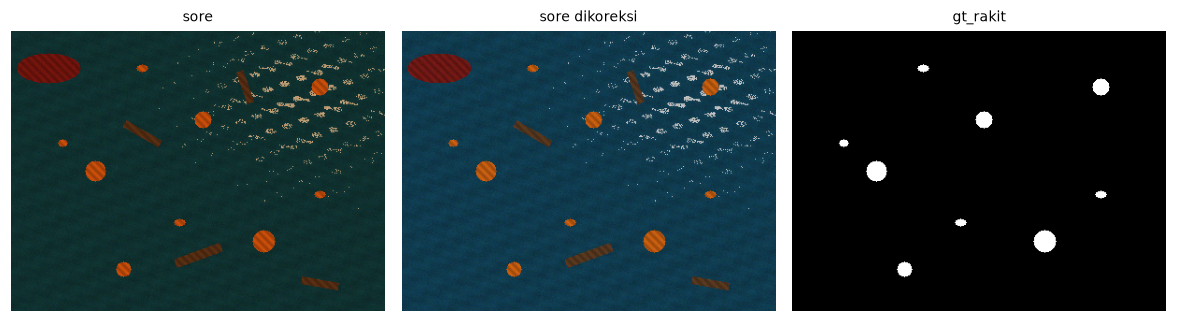

In [18]:
# TODO 5.3 — Koreksi warna cahaya. Kilau adalah pantulan cermin sumber cahaya, jadi warnanya menaksir warna cahaya.
#            Ambil 0,5 % piksel paling terang (jumlah R+G+B) pada laut['sore'], hitung rerata warnanya w = (wR, wG, wB),
#            kalikan tiap kanal dengan max(w)/w_i (transformasi per komponen, Eq. 6-38), lalu jalankan ulang TODO 5.2.
sore = laut['sore'].astype(float)
jumlah = sore.sum(axis=2)
m_terang = jumlah >= np.percentile(jumlah, 99.5)
w = sore[m_terang].mean(axis=0)
gain = w.max() / w
sore_koreksi = np.clip(np.floor(sore * gain + 0.5), 0, 255).astype(np.uint8)
print(f'w = ({w[0]:.1f}, {w[1]:.1f}, {w[2]:.1f}); gain = ({gain[0]:.3f}, {gain[1]:.3f}, {gain[2]:.3f}); '
      f'piksel kilau={int(m_terang.sum())}')
hsv_s = cv2.cvtColor(laut['sore'], cv2.COLOR_RGB2HSV)
print(f"Median HSV sebelum koreksi: rakit H={np.median(hsv_s[gt_rakit], axis=0)[0]:.0f} S={np.median(hsv_s[gt_rakit], axis=0)[1]:.0f} V={np.median(hsv_s[gt_rakit], axis=0)[2]:.0f}; kayu H={np.median(hsv_s[m_kayu], axis=0)[0]:.0f} S={np.median(hsv_s[m_kayu], axis=0)[1]:.0f} V={np.median(hsv_s[m_kayu], axis=0)[2]:.0f}")
for label, im in (('sebelum', laut['sore']), ('sesudah', sore_koreksi)):
    print(f'--- sore {label} koreksi ---')
    for nama, (m, kayu_px) in uji_perairan(im).items():
        print(f"{nama:12s} IoU={m['iou']:.3f} presisi={m['presisi']:.3f} recall={m['recall']:.3f} "
              f"komponen={m['komponen']:3d} piksel_kayu={kayu_px}")
hsv_k = cv2.cvtColor(sore_koreksi, cv2.COLOR_RGB2HSV)
print(f"Median HSV sesudah koreksi: rakit H={np.median(hsv_k[gt_rakit], axis=0)[0]:.0f} "
      f"S={np.median(hsv_k[gt_rakit], axis=0)[1]:.0f} V={np.median(hsv_k[gt_rakit], axis=0)[2]:.0f}; "
      f"kayu H={np.median(hsv_k[m_kayu], axis=0)[0]:.0f} "
      f"S={np.median(hsv_k[m_kayu], axis=0)[1]:.0f} V={np.median(hsv_k[m_kayu], axis=0)[2]:.0f}")
tampil([laut['sore'], sore_koreksi, gt_rakit], ['sore', 'sore dikoreksi', 'gt_rakit'], kolom=3, cmap='gray')


**Analisis 5.** (a) Mengapa RGB Euclid dan Lab a*b* yang hampir sempurna di siang runtuh di berawan, sedangkan HSV tidak? (b) Cahaya sore menggagalkan HSV juga. Besaran mana yang bergeser (lihat median TODO 5.1) dan mengapa ambang S = 200 menjadi rapuh? (c) Taksiran warna cahaya dari kilau ternyata sangat tepat. Sebutkan **dua** alasan mengapa hasil ini tidak akan seakurat itu pada foto udara sungguhan. (d) Usulkan urutan pengolahan untuk tim SAR, mulai dari citra mentah sampai masker kandidat rakit.

*Jawaban:* (a) Pada siang hari, RGB dan Lab a*b* sangat baik dengan IoU `0.991`. Saat berawan, nilainya turun menjadi `0.873` dan `0.903` karena objek menjadi lebih gelap. HSV tetap tinggi, yaitu `0.988`, karena jenis warna dan tingkat kejenuhannya lebih stabil. (b) Rakit dan kayu memiliki hue yang sama, yaitu `13`, sehingga hue saja tidak cukup. Perbedaannya ada pada saturasi dan kecerahan: rakit memiliki `S=233,V=217`, sedangkan kayu `S=164,V=95`. Pada sore, S kayu naik menjadi `200`, tepat menyentuh batas `S>=200`; akibatnya `800` piksel kayu salah terdeteksi dan IoU turun menjadi `0.682`. (c) Hasil koreksi bisa kurang tepat karena kilau dapat terlalu terang hingga sensor kamera kehilangan detail, dan pantulan nyata biasanya tercampur warna air, kabut, atau bayangan. (d) Urutan sederhana untuk tim SAR: koreksi cahaya, ubah ke HSV atau Lab, pilih piksel kandidat, rapikan masker dengan operasi morfologi, buang bagian terlalu kecil, lalu periksa kandidat secara visual.

## Bagian 6 &mdash; Laporan ilmiah dan pengumpulan (10 menit)

Indikator kedua Sub-CPMK-4 menilai **laporan praktikum sesuai kaidah penulisan ilmiah**. Laporan Bagian 4&ndash;5 disusun maksimal 4 halaman dengan struktur:

1. **Pendahuluan** &mdash; persoalan (deteksi objek berdasarkan warna di bawah cahaya berubah) dan tujuan percobaan.
2. **Metode** &mdash; ruang warna dan aturan yang diuji, **rumus beserta nomor persamaan Gonzalez**, cara memilih ambang, ukuran evaluasi (IoU, presisi, recall).
3. **Hasil** &mdash; satu tabel bernomor dan berjudul (metode &times; kondisi), satu gambar bernomor dengan keterangan. Angka **disalin dari keluaran notebook**, bukan dibulatkan sesuka hati.
4. **Pembahasan** &mdash; justifikasi pilihan ruang warna **dengan angka**; minimal satu paragraf **batas keberlakuan** (kapan metode Anda gagal dan mengapa).
5. **Kesimpulan** &mdash; menjawab tujuan, tanpa klaim baru.
6. **Daftar rujukan** &mdash; gaya Harvard; minimal Gonzalez dan Woods (2018).

Periksa sebelum mengumpulkan:
- [ ] Semua sel berjalan tanpa galat dari atas (Kernel &rarr; Restart & Run All).
- [ ] Setiap blok Analisis memuat angka dari keluaran.
- [ ] Tabel dan gambar di laporan bernomor, berjudul, dan dirujuk di teks.
- [ ] Tidak ada klaim "HSV selalu lebih baik" tanpa syarat.